# 03 — U-Net Baseline

## Objective

Train and evaluate a baseline U-Net model for binary brain tumor
segmentation using the BRISC 2025 dataset.

This notebook reuses the fixed data partitions and preprocessing
configuration generated in `02_data_preparation.ipynb`.

### Experimental protocol

- Training: 3,345 images
- Validation: 588 images
- Test: 853 images
- Input resolution: 256 × 256
- MRI channels: 1
- Segmentation classes: background and tumor
- Primary evaluation metrics: Dice and IoU

The corrected test set will remain reserved for final evaluation.

In [1]:
from pathlib import Path
import urllib.request
import json
import pandas as pd

REPO = "nouraastafofana-droid/brain-tumor-mri-segmentation"
BRANCH = "main"

ARTIFACT_DIR = Path("/content/artifacts/data_preparation")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    f"https://raw.githubusercontent.com/{REPO}/{BRANCH}/"
    "artifacts/data_preparation"
)

filenames = [
    "train.csv",
    "val.csv",
    "test.csv",
    "preprocessing_config.json",
    "split_summary.json"
]

for filename in filenames:
    url = f"{BASE_URL}/{filename}"
    destination = ARTIFACT_DIR / filename

    urllib.request.urlretrieve(url, destination)
    print("Downloaded:", filename)

train_df = pd.read_csv(ARTIFACT_DIR / "train.csv")
val_df = pd.read_csv(ARTIFACT_DIR / "val.csv")
test_df = pd.read_csv(ARTIFACT_DIR / "test.csv")

with open(ARTIFACT_DIR / "preprocessing_config.json") as f:
    config = json.load(f)

with open(ARTIFACT_DIR / "split_summary.json") as f:
    split_summary = json.load(f)

print("\nLoaded partitions:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nPreprocessing configuration:")
print(json.dumps(config, indent=2))

Downloaded: train.csv
Downloaded: val.csv
Downloaded: test.csv
Downloaded: preprocessing_config.json
Downloaded: split_summary.json

Loaded partitions:
Train: 3345
Validation: 588
Test: 853

Preprocessing configuration:
{
  "dataset": "BRISC 2025",
  "image_size": [
    256,
    256
  ],
  "image_channels": 1,
  "mask_channels": 1,
  "image_normalization": "divide_by_255",
  "mask_threshold": 128,
  "image_interpolation": "bilinear",
  "mask_interpolation": "nearest",
  "batch_size": 16,
  "random_state": 42,
  "validation_fraction": 0.15
}


## 3.2 - Reconstruct the TensorFlow data pipeline

The original BRISC dataset is downloaded to provide the MRI images
and segmentation masks referenced by the saved CSV manifests.

The fixed train, validation, and corrected test partitions are
loaded directly from the artifacts produced in Notebook 02.

In [2]:
from google.colab import userdata
from pathlib import Path
import os

DATA_ROOT = Path("/content/data")
BRISC_ROOT = DATA_ROOT / "brisc2025"

if not (BRISC_ROOT / "manifest.csv").exists():

    print("Downloading BRISC 2025...")

    os.environ["KAGGLE_API_TOKEN"] = userdata.get(
        "KAGGLE_API_TOKEN"
    )

    DATA_ROOT.mkdir(parents=True, exist_ok=True)

    !kaggle datasets download \
        -d briscdataset/brisc2025 \
        -p /content/data \
        --unzip

else:
    print("BRISC dataset already available.")

assert (BRISC_ROOT / "manifest.csv").exists()

print("Dataset ready.")

Dataset URL: https://www.kaggle.com/datasets/briscdataset/brisc2025
License(s): Attribution 4.0 International (CC BY 4.0)
100% 250M/250M [00:02<00:00, 102MB/s]

Dataset ready.


In [3]:
import tensorflow as tf

IMAGE_SIZE = tuple(config["image_size"])
BATCH_SIZE = config["batch_size"]
MASK_THRESHOLD = config["mask_threshold"]
RANDOM_STATE = config["random_state"]

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_pair(image_path, mask_path):

    # Load MRI
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )
    image.set_shape([None, None, 1])

    # Load mask
    mask = tf.io.read_file(mask_path)
    mask = tf.io.decode_png(mask, channels=1)

    # Resize
    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method=config["image_interpolation"]
    )

    mask = tf.image.resize(
        mask,
        IMAGE_SIZE,
        method=config["mask_interpolation"]
    )

    # Normalize MRI and binarize mask
    image = tf.cast(image, tf.float32) / 255.0
    mask = tf.cast(mask >= MASK_THRESHOLD, tf.float32)

    return image, mask

In [4]:
def build_dataset(df, training=False):

    image_paths = [
        str(BRISC_ROOT / path)
        for path in df["image_relative_path"]
    ]

    mask_paths = [
        str(BRISC_ROOT / path)
        for path in df["mask_relative_path"]
    ]

    assert all(Path(p).is_file() for p in image_paths)
    assert all(Path(p).is_file() for p in mask_paths)

    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, mask_paths)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        preprocess_pair,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = build_dataset(train_df, training=True)
val_ds = build_dataset(val_df)
test_ds = build_dataset(test_df)

print("Datasets successfully reconstructed.")

for name, ds in [
    ("Train", train_ds),
    ("Validation", val_ds),
    ("Test", test_ds)
]:
    images, masks = next(iter(ds))

    print(f"\n{name}:")
    print("Images:", images.shape)
    print("Masks:", masks.shape)

Datasets successfully reconstructed.

Train:
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)

Validation:
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)

Test:
Images: (16, 256, 256, 1)
Masks: (16, 256, 256, 1)


## 3.3 - U-Net Architecture

A baseline 2D U-Net is implemented for binary brain tumor segmentation.

The architecture consists of:
- A four-level convolutional encoder.
- A bottleneck with 512 filters.
- A symmetric decoder with skip connections.
- A single-channel sigmoid output producing pixel-wise tumor probabilities.

The model receives grayscale MRI images of shape (256, 256, 1)
and predicts segmentation maps of the same spatial dimensions.

This baseline uses a conventional U-Net architecture without
pretrained weights or attention mechanisms.

In [5]:
from tensorflow.keras import layers, Model

def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    x = layers.Conv2D(
        filters, 3, padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    )(x)

    return x


def encoder_block(x, filters):
    skip = conv_block(x, filters)
    pooled = layers.MaxPooling2D(pool_size=(2, 2))(skip)
    return skip, pooled


def decoder_block(x, skip, filters):
    x = layers.Conv2DTranspose(
        filters, kernel_size=2, strides=2,
        padding="same"
    )(x)

    x = layers.Concatenate()([x, skip])
    x = conv_block(x, filters)

    return x


def build_unet(input_shape=(256, 256, 1)):
    inputs = layers.Input(shape=input_shape)

    # Encoder
    s1, p1 = encoder_block(inputs, 32)
    s2, p2 = encoder_block(p1, 64)
    s3, p3 = encoder_block(p2, 128)
    s4, p4 = encoder_block(p3, 256)

    # Bottleneck
    b = conv_block(p4, 512)

    # Decoder
    d1 = decoder_block(b, s4, 256)
    d2 = decoder_block(d1, s3, 128)
    d3 = decoder_block(d2, s2, 64)
    d4 = decoder_block(d3, s1, 32)

    # Pixel-wise tumor probability
    outputs = layers.Conv2D(
        1, kernel_size=1,
        activation="sigmoid"
    )(d4)

    return Model(inputs, outputs, name="UNet_Baseline")


model = build_unet(
    input_shape=(*IMAGE_SIZE, 1)
)

model.summary()

Model: "UNet_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_3[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_8[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 32, 32,    │    524,544 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ conv2d_transpose

 Total params: 7,759,521 (29.60 MB)

 Trainable params: 7,759,521 (29.60 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Verify model output shape without training

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

assert model.input_shape == (None, 256, 256, 1)
assert model.output_shape == (None, 256, 256, 1)

print("U-Net architecture validated.")

Input shape: (None, 256, 256, 1)
Output shape: (None, 256, 256, 1)
U-Net architecture validated.


## 3.4 - Loss Function and Evaluation Metrics

Brain tumor segmentation is a highly imbalanced binary segmentation
task, with tumor regions occupying a small proportion of MRI pixels.

To address this imbalance, the baseline uses a combined loss:

**Total Loss = Binary Cross-Entropy + Soft Dice Loss**

Binary Cross-Entropy provides pixel-wise supervision, while Soft Dice
Loss encourages overlap between predicted and ground-truth tumor regions.

Two threshold-based evaluation metrics are monitored:

- **Dice coefficient:** measures overlap between predicted and
  ground-truth segmentation masks.
- **Intersection over Union (IoU):** measures the ratio between
  intersection and union of the two masks.

Both metrics use a probability threshold of 0.5.

Metrics are computed per image and averaged across the batch.

In [7]:
import tensorflow as tf

SMOOTH = 1e-6

# Soft Dice coefficient for optimization
def soft_dice_coefficient(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = (1, 2, 3)

    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    denominator = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
    )

    dice = (2.0 * intersection + SMOOTH) / (
        denominator + SMOOTH
    )

    return tf.reduce_mean(dice)


def dice_loss(y_true, y_pred):
    return 1.0 - soft_dice_coefficient(y_true, y_pred)


bce = tf.keras.losses.BinaryCrossentropy()

def bce_dice_loss(y_true, y_pred):
    return bce(y_true, y_pred) + dice_loss(y_true, y_pred)


# Hard Dice coefficient for evaluation
def dice_coefficient(y_true, y_pred):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)

    axes = (1, 2, 3)

    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    denominator = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
    )

    dice = (2.0 * intersection + SMOOTH) / (
        denominator + SMOOTH
    )

    return tf.reduce_mean(dice)


# Hard IoU for evaluation
def iou_coefficient(y_true, y_pred):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.5, tf.float32)

    axes = (1, 2, 3)

    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)

    union = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
        - intersection
    )

    iou = (intersection + SMOOTH) / (union + SMOOTH)

    return tf.reduce_mean(iou)

In [8]:
LEARNING_RATE = 1e-4

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=bce_dice_loss,
    metrics=[
        dice_coefficient,
        iou_coefficient
    ]
)

print("U-Net compiled successfully.")

U-Net compiled successfully.


In [9]:
# Perfect prediction
y_true = tf.constant(
    [[[[1.0], [0.0]], [[1.0], [0.0]]]]
)

y_perfect = tf.identity(y_true)

# Completely incorrect prediction
y_wrong = 1.0 - y_true

print(
    "Perfect Dice:",
    float(dice_coefficient(y_true, y_perfect))
)

print(
    "Perfect IoU:",
    float(iou_coefficient(y_true, y_perfect))
)

print(
    "Wrong Dice:",
    float(dice_coefficient(y_true, y_wrong))
)

print(
    "Wrong IoU:",
    float(iou_coefficient(y_true, y_wrong))
)

Perfect Dice: 1.0
Perfect IoU: 1.0
Wrong Dice: 2.499999425253918e-07
Wrong IoU: 2.499999425253918e-07


## 3.5 - Baseline U-Net Training

The baseline U-Net is trained using the fixed training and
validation partitions.

Training configuration:
- Optimizer: Adam
- Initial learning rate: 1e-4
- Loss: Binary Cross-Entropy + Soft Dice Loss
- Maximum epochs: 30
- Batch size: 16

Early stopping and learning-rate reduction are applied based
on validation loss.

The model checkpoint with the lowest validation loss is saved
for subsequent evaluation.

In [10]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "unet_baseline_best.keras"

print("Best model will be saved to:", BEST_MODEL_PATH)

Mounted at /content/drive
Best model will be saved to: /content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints/unet_baseline_best.keras


In [11]:
from tensorflow.keras.callbacks import (
    ModelCheckpoint,
    EarlyStopping,
    ReduceLROnPlateau,
    CSVLogger
)

callbacks = [
    ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        mode="min",
        verbose=1
    ),

    CSVLogger(
        str(CHECKPOINT_DIR / "unet_baseline_training_log.csv")
    )
]

print("Training callbacks configured.")

Training callbacks configured.


In [12]:
EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
210/210 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step - dice_coefficient: 0.0928 - iou_coefficient: 0.0656 - loss: 1.0562
Epoch 1: val_loss improved from None to 0.61636, saving model to /content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints/unet_baseline_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints/unet_baseline_best.keras
210/210 ━━━━━━━━━━━━━━━━━━━━ 140s 463ms/step - dice_coefficient: 0.2431 - iou_coefficient: 0.1773 - loss: 0.8656 - val_dice_coefficient: 0.4907 - val_iou_coefficient: 0.3685 - val_loss: 0.6164 - learning_rate: 1.0000e-04
Epoch 2/30
209/210 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - dice_coefficient: 0.4918 - iou_coefficient: 0.3811 - loss: 0.6051
Epoch 2: val_loss improved from 0.61636 to 0.45179, saving model to /content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints/unet_baseline_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/brain-tumor-mri-segmentation/checkpoints/u

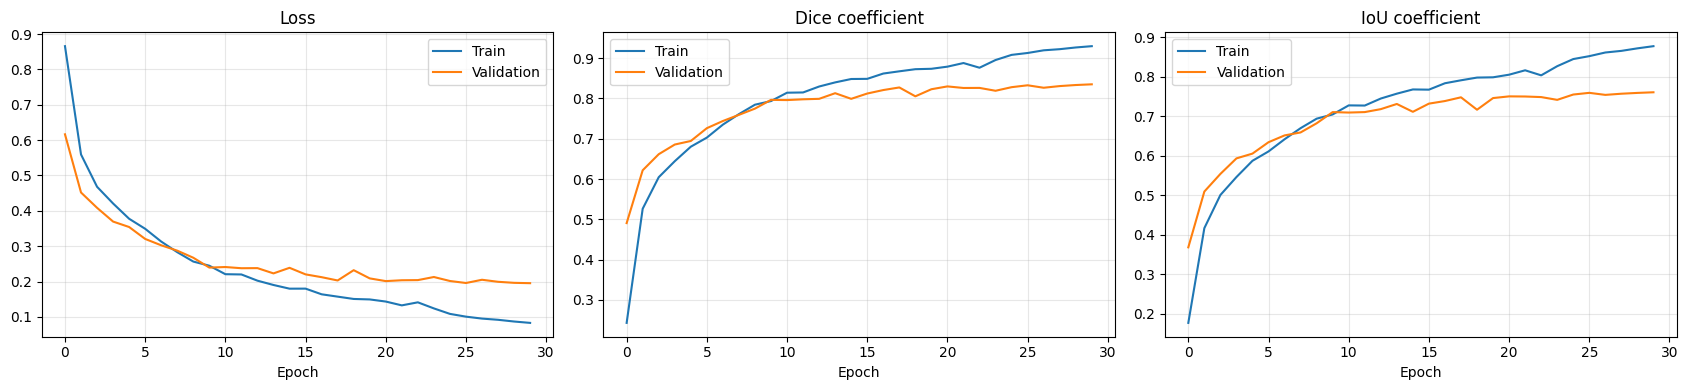

Best epoch: 30
Best validation loss: 0.19532760977745056


In [13]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

metrics = [
    ("loss", "Loss"),
    ("dice_coefficient", "Dice coefficient"),
    ("iou_coefficient", "IoU coefficient")
]

for ax, (metric, title) in zip(axes, metrics):
    ax.plot(
        history_df[metric],
        label="Train"
    )
    ax.plot(
        history_df[f"val_{metric}"],
        label="Validation"
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_epoch = history_df["val_loss"].idxmin() + 1

print("Best epoch:", best_epoch)
print(
    "Best validation loss:",
    history_df["val_loss"].min()
)

### Baseline Training Results

The baseline U-Net completed 30 training epochs.

The best checkpoint was obtained at epoch 30, with:
- Validation loss: 0.1953
- Validation Dice coefficient: 0.8351
- Validation IoU coefficient: 0.7610

Training performance continued to improve throughout the experiment,
while validation metrics showed signs of plateauing.

The final training Dice coefficient reached 0.9297, suggesting a
generalization gap relative to validation performance.

The learning-rate scheduler reduced the learning rate during training.

These results establish the initial segmentation baseline.
Qualitative validation inspection and held-out test evaluation
are required before drawing conclusions about generalization.

## 3.6 - Qualitative Validation Predictions

Predicted segmentation masks are visually compared with ground-truth
annotations on validation MRI images.

This inspection helps identify segmentation quality, missed tumor
regions, false positives, and boundary inaccuracies.

The validation partition is used for qualitative inspection.
The corrected test partition remains untouched until final evaluation.

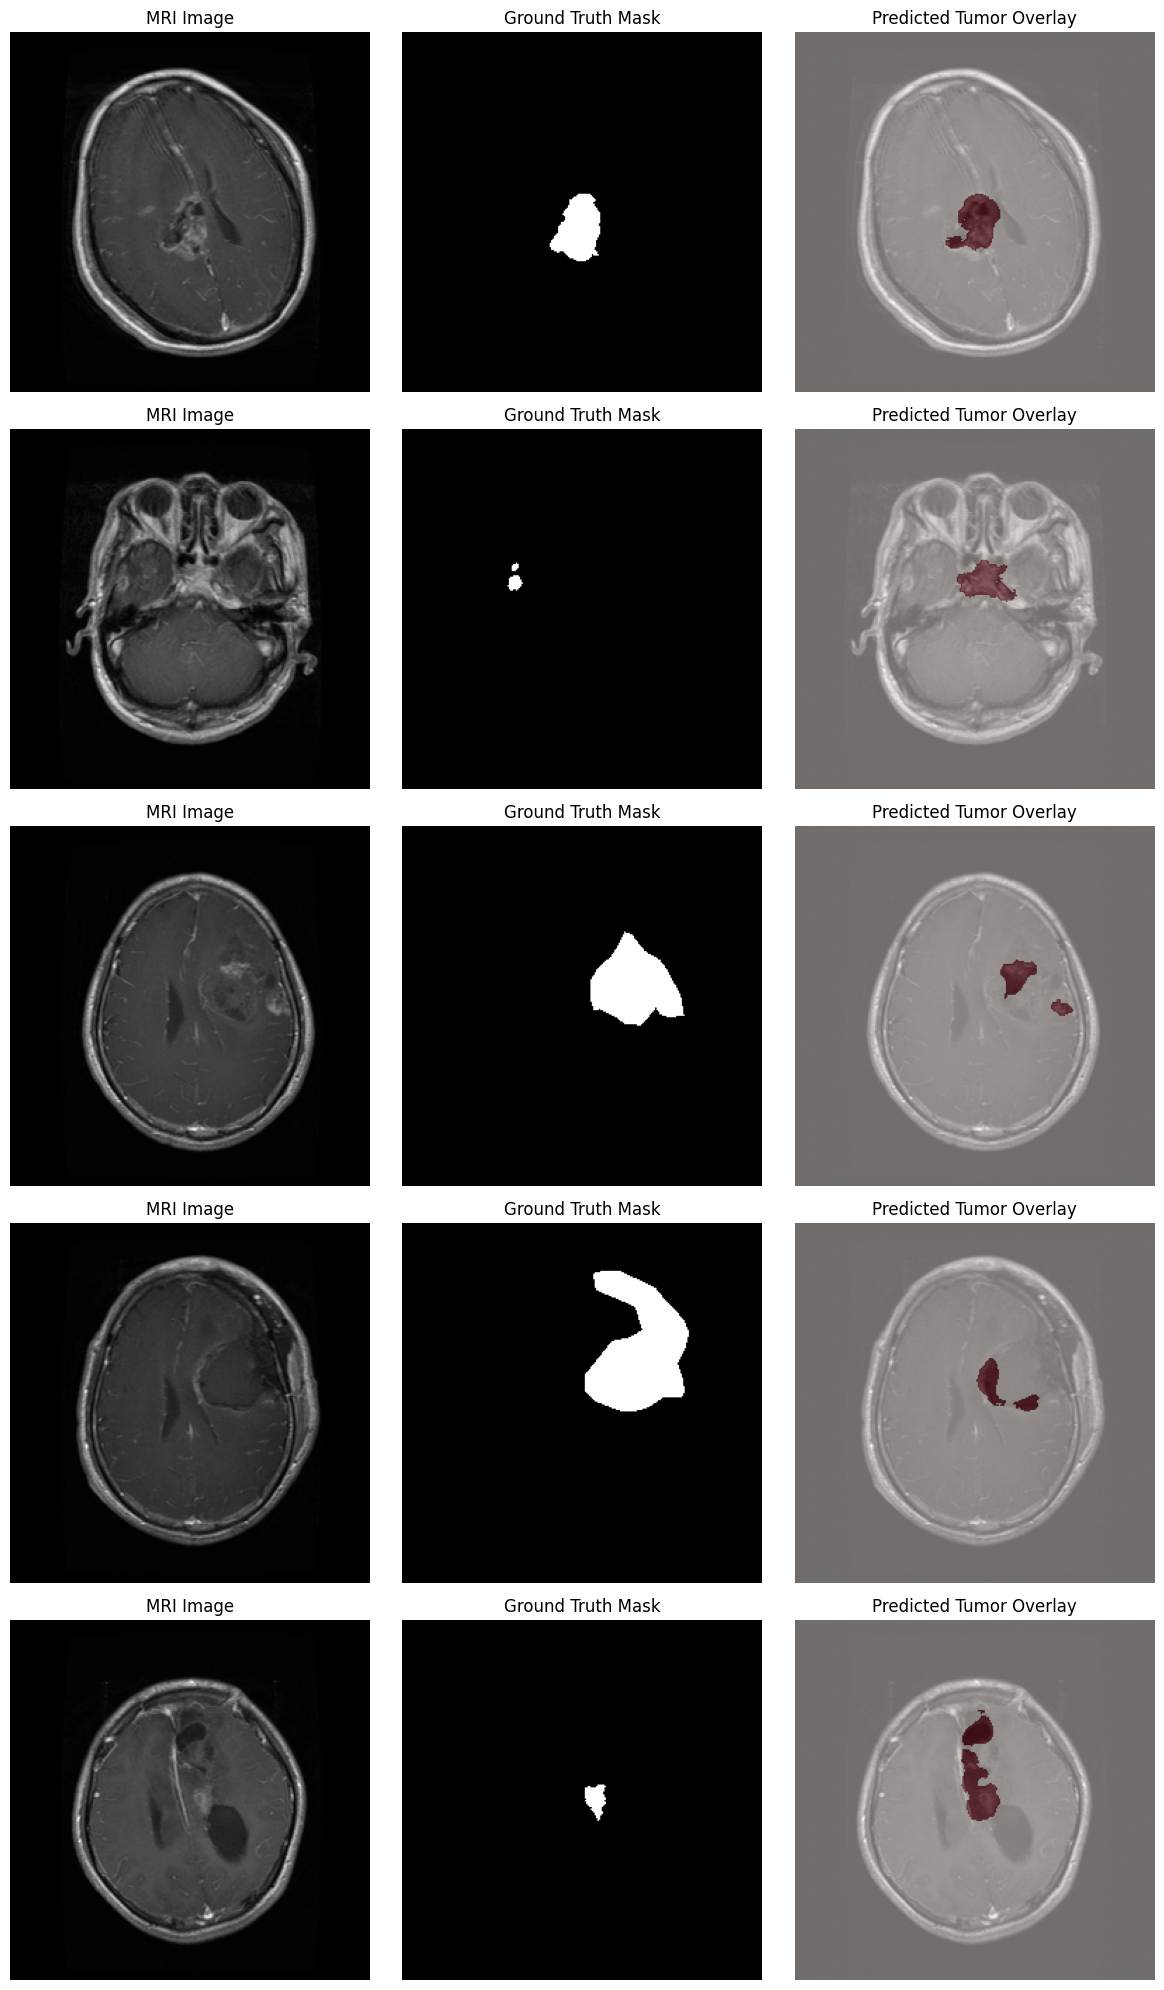

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Select a validation batch
val_images, val_masks = next(iter(val_ds))

# Predict tumor probabilities
val_predictions = model.predict(val_images, verbose=0)

# Convert probabilities to binary masks
val_pred_masks = (val_predictions >= 0.5).astype(np.float32)

# Display 5 examples
n_samples = 5

fig, axes = plt.subplots(n_samples, 3, figsize=(12, 4 * n_samples))

for i in range(n_samples):
    axes[i, 0].imshow(val_images[i, :, :, 0], cmap="gray")
    axes[i, 0].set_title("MRI Image")

    axes[i, 1].imshow(val_masks[i, :, :, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(val_images[i, :, :, 0], cmap="gray")
    axes[i, 2].imshow(
        val_pred_masks[i, :, :, 0],
        cmap="Reds",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("Predicted Tumor Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

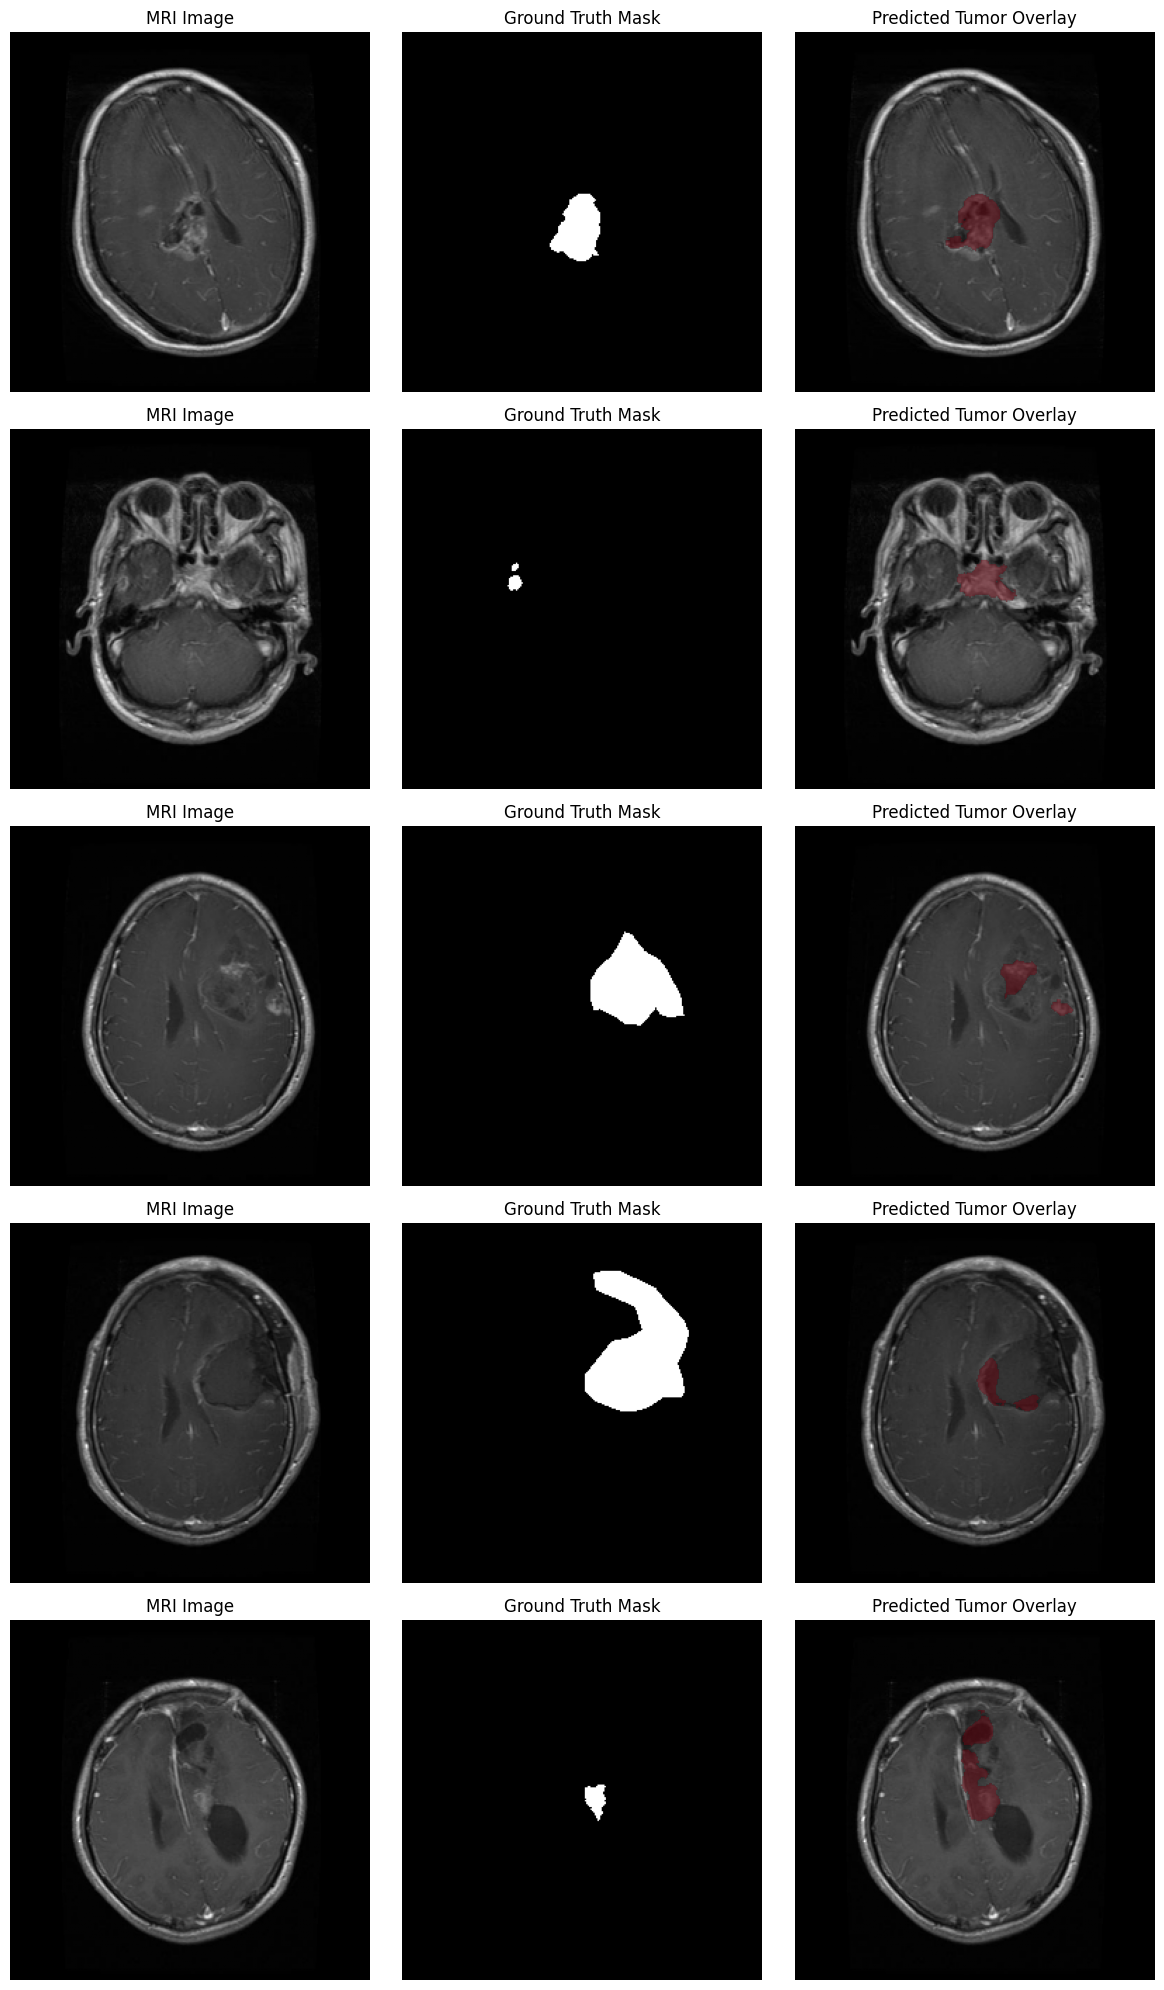

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Select a validation batch
val_images, val_masks = next(iter(val_ds))

# Predict tumor probabilities
val_predictions = model.predict(val_images, verbose=0)

# Convert probabilities to binary masks
val_pred_masks = (val_predictions >= 0.5).astype(np.float32)

# Display 5 examples
n_samples = 5

fig, axes = plt.subplots(n_samples, 3, figsize=(12, 4 * n_samples))

for i in range(n_samples):
    axes[i, 0].imshow(val_images[i, :, :, 0], cmap="gray")
    axes[i, 0].set_title("MRI Image")

    axes[i, 1].imshow(val_masks[i, :, :, 0], cmap="gray")
    axes[i, 1].set_title("Ground Truth Mask")

    axes[i, 2].imshow(val_images[i, :, :, 0], cmap="gray")
    predicted_mask = np.ma.masked_where(
        val_pred_masks[i, :, :, 0] == 0,
        val_pred_masks[i, :, :, 0])
    axes[i, 2].imshow(
        predicted_mask,
        cmap="Reds",
        alpha=0.5,
        vmin=0,
        vmax=1)
    axes[i, 2].set_title("Predicted Tumor Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 3.7 - Held-Out Test Evaluation

The best baseline U-Net checkpoint is evaluated on the corrected
held-out test partition of 853 MRI images.

Evaluation uses a fixed probability threshold of 0.5.

Dice and IoU are computed independently for each image, enabling
overall performance assessment and subgroup analysis by tumor type
and MRI acquisition plane.

In [16]:
import numpy as np
import pandas as pd

# The model already contains the best weights restored by EarlyStopping.
# Test dataset is deterministic (no shuffling).

test_dice_scores = []
test_iou_scores = []

for images, masks in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true = masks.numpy() >= 0.5
    y_pred = predictions >= 0.5

    intersection = np.sum(
        y_true & y_pred, axis=(1, 2, 3)
    )

    true_area = np.sum(y_true, axis=(1, 2, 3))
    pred_area = np.sum(y_pred, axis=(1, 2, 3))

    dice = (
        2 * intersection + 1e-6
    ) / (
        true_area + pred_area + 1e-6
    )

    union = true_area + pred_area - intersection

    iou = (
        intersection + 1e-6
    ) / (
        union + 1e-6
    )

    test_dice_scores.extend(dice.tolist())
    test_iou_scores.extend(iou.tolist())

assert len(test_dice_scores) == len(test_df)
assert len(test_iou_scores) == len(test_df)

test_results = test_df.copy().reset_index(drop=True)

test_results["dice"] = test_dice_scores
test_results["iou"] = test_iou_scores

print("Evaluated images:", len(test_results))
print("Mean Dice:", round(test_results["dice"].mean(), 4))
print("Mean IoU:", round(test_results["iou"].mean(), 4))
print("Median Dice:", round(test_results["dice"].median(), 4))
print("Median IoU:", round(test_results["iou"].median(), 4))

Evaluated images: 853
Mean Dice: 0.8209
Mean IoU: 0.7412
Median Dice: 0.9142
Median IoU: 0.842


In [17]:
print("Performance by tumor type:")

display(
    test_results.groupby("tumor_label")[["dice", "iou"]]
    .agg(["mean", "median", "std", "count"])
    .round(4)
)

print("\nPerformance by MRI plane:")

display(
    test_results.groupby("plane_label")[["dice", "iou"]]
    .agg(["mean", "median", "std", "count"])
    .round(4)
)

Performance by tumor type:


dice                           iou                      
               mean  median     std count    mean  median     std count
tumor_label                                                            
glioma       0.6698  0.7806  0.2986   254  0.5693  0.6401  0.2991   254
meningioma   0.9256  0.9566  0.0982   304  0.8729  0.9168  0.1277   304
pituitary    0.8432  0.9013  0.1561   295  0.7533  0.8203  0.1857   295


Performance by MRI plane:


dice                           iou                      
               mean  median     std count    mean  median     std count
plane_label                                                            
axial        0.8090  0.9190  0.2430   342  0.7317  0.8502  0.2623   342
coronal      0.8194  0.9013  0.2240   254  0.7383  0.8204  0.2390   254
sagittal     0.8383  0.9223  0.1871   257  0.7567  0.8558  0.2213   257

## 3.8 - Baseline Results and Reproducibility

The baseline U-Net achieved a mean Dice coefficient of 0.8209
and a mean IoU of 0.7412 on the corrected test partition
of 853 MRI images.

Performance varied substantially across tumor types:
- Glioma: Dice 0.6698
- Meningioma: Dice 0.9256
- Pituitary: Dice 0.8432

The results suggest that glioma segmentation is the main
limitation of the current baseline.

In [18]:
from pathlib import Path
import json

RESULTS_DIR = Path(
    "/content/drive/MyDrive/brain-tumor-mri-segmentation/results"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save per-image test results
test_results.to_csv(
    RESULTS_DIR / "unet_baseline_test_predictions.csv",
    index=False
)

# Save overall metrics
summary = {
    "model": "UNet_Baseline",
    "test_images": len(test_results),
    "threshold": 0.5,
    "mean_dice": float(test_results["dice"].mean()),
    "median_dice": float(test_results["dice"].median()),
    "mean_iou": float(test_results["iou"].mean()),
    "median_iou": float(test_results["iou"].median()),
    "by_tumor_type": test_results.groupby("tumor_label")[
        ["dice", "iou"]
    ].mean().round(4).to_dict(orient="index"),
    "by_plane": test_results.groupby("plane_label")[
        ["dice", "iou"]
    ].mean().round(4).to_dict(orient="index")
}

with open(
    RESULTS_DIR / "unet_baseline_test_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=2)

print("Baseline test results saved successfully.")

Baseline test results saved successfully.


## 3.9 - Glioma Error Analysis

Glioma segmentation achieved the lowest mean Dice score among
the three tumor categories.

This analysis examines the distribution of glioma Dice scores
and identifies poorly segmented cases.

The objective is to characterize baseline failure patterns
before proposing improvements to the segmentation model.

Glioma images: 254
Mean Dice: 0.6698
Median Dice: 0.7806

Dice distribution:


,dice
count,254.0000
mean,0.6698
std,0.2986
min,0.0000
10%,0.1083
25%,0.5114
50%,0.7806
75%,0.9094
90%,0.9527
max,0.9806


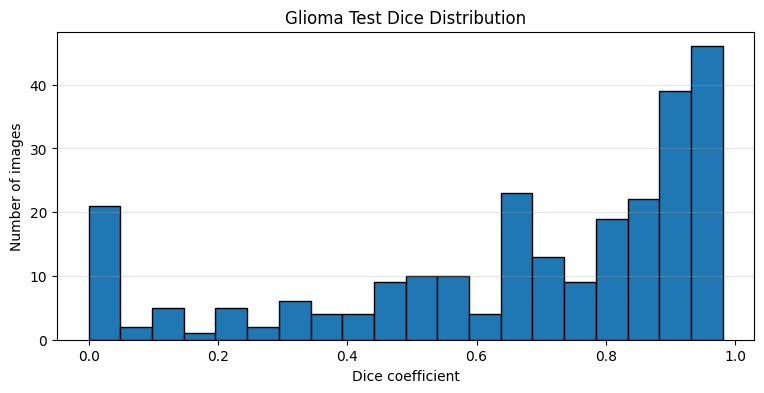


10 worst glioma predictions:


,image_relative_path,plane_label,dice,iou
44,segmentation_task/test/images/brisc2025_test_0...,axial,3.167564e-10,3.167564e-10
105,segmentation_task/test/images/brisc2025_test_0...,coronal,3.590664e-10,3.590664e-10
40,segmentation_task/test/images/brisc2025_test_0...,axial,5.614823e-10,5.614823e-10
6,segmentation_task/test/images/brisc2025_test_0...,axial,9.737098e-10,9.737098e-10
59,segmentation_task/test/images/brisc2025_test_0...,axial,1.288660e-09,1.288660e-09
142,segmentation_task/test/images/brisc2025_test_0...,coronal,1.658375e-09,1.658375e-09
11,segmentation_task/test/images/brisc2025_test_0...,axial,1.828154e-09,1.828154e-09
130,segmentation_task/test/images/brisc2025_test_0...,coronal,1.841621e-09,1.841621e-09
4,segmentation_task/test/images/brisc2025_test_0...,axial,1.862197e-09,1.862197e-09
206,segmentation_task/test/images/brisc2025_test_0...,sagittal,1.988072e-09,1.988072e-09


In [19]:
import matplotlib.pyplot as plt

glioma_results = (
    test_results[test_results["tumor_label"] == "glioma"]
    .copy()
    .sort_values("dice")
)

print("Glioma images:", len(glioma_results))
print("Mean Dice:", round(glioma_results["dice"].mean(), 4))
print("Median Dice:", round(glioma_results["dice"].median(), 4))

print("\nDice distribution:")
display(
    glioma_results["dice"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90])
    .round(4)
)

fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(glioma_results["dice"], bins=20, edgecolor="black")

ax.set_title("Glioma Test Dice Distribution")
ax.set_xlabel("Dice coefficient")
ax.set_ylabel("Number of images")
ax.grid(axis="y", alpha=0.3)

plt.show()

print("\n10 worst glioma predictions:")
display(
    glioma_results[
        ["image_relative_path", "plane_label", "dice", "iou"]
    ].head(10)
)

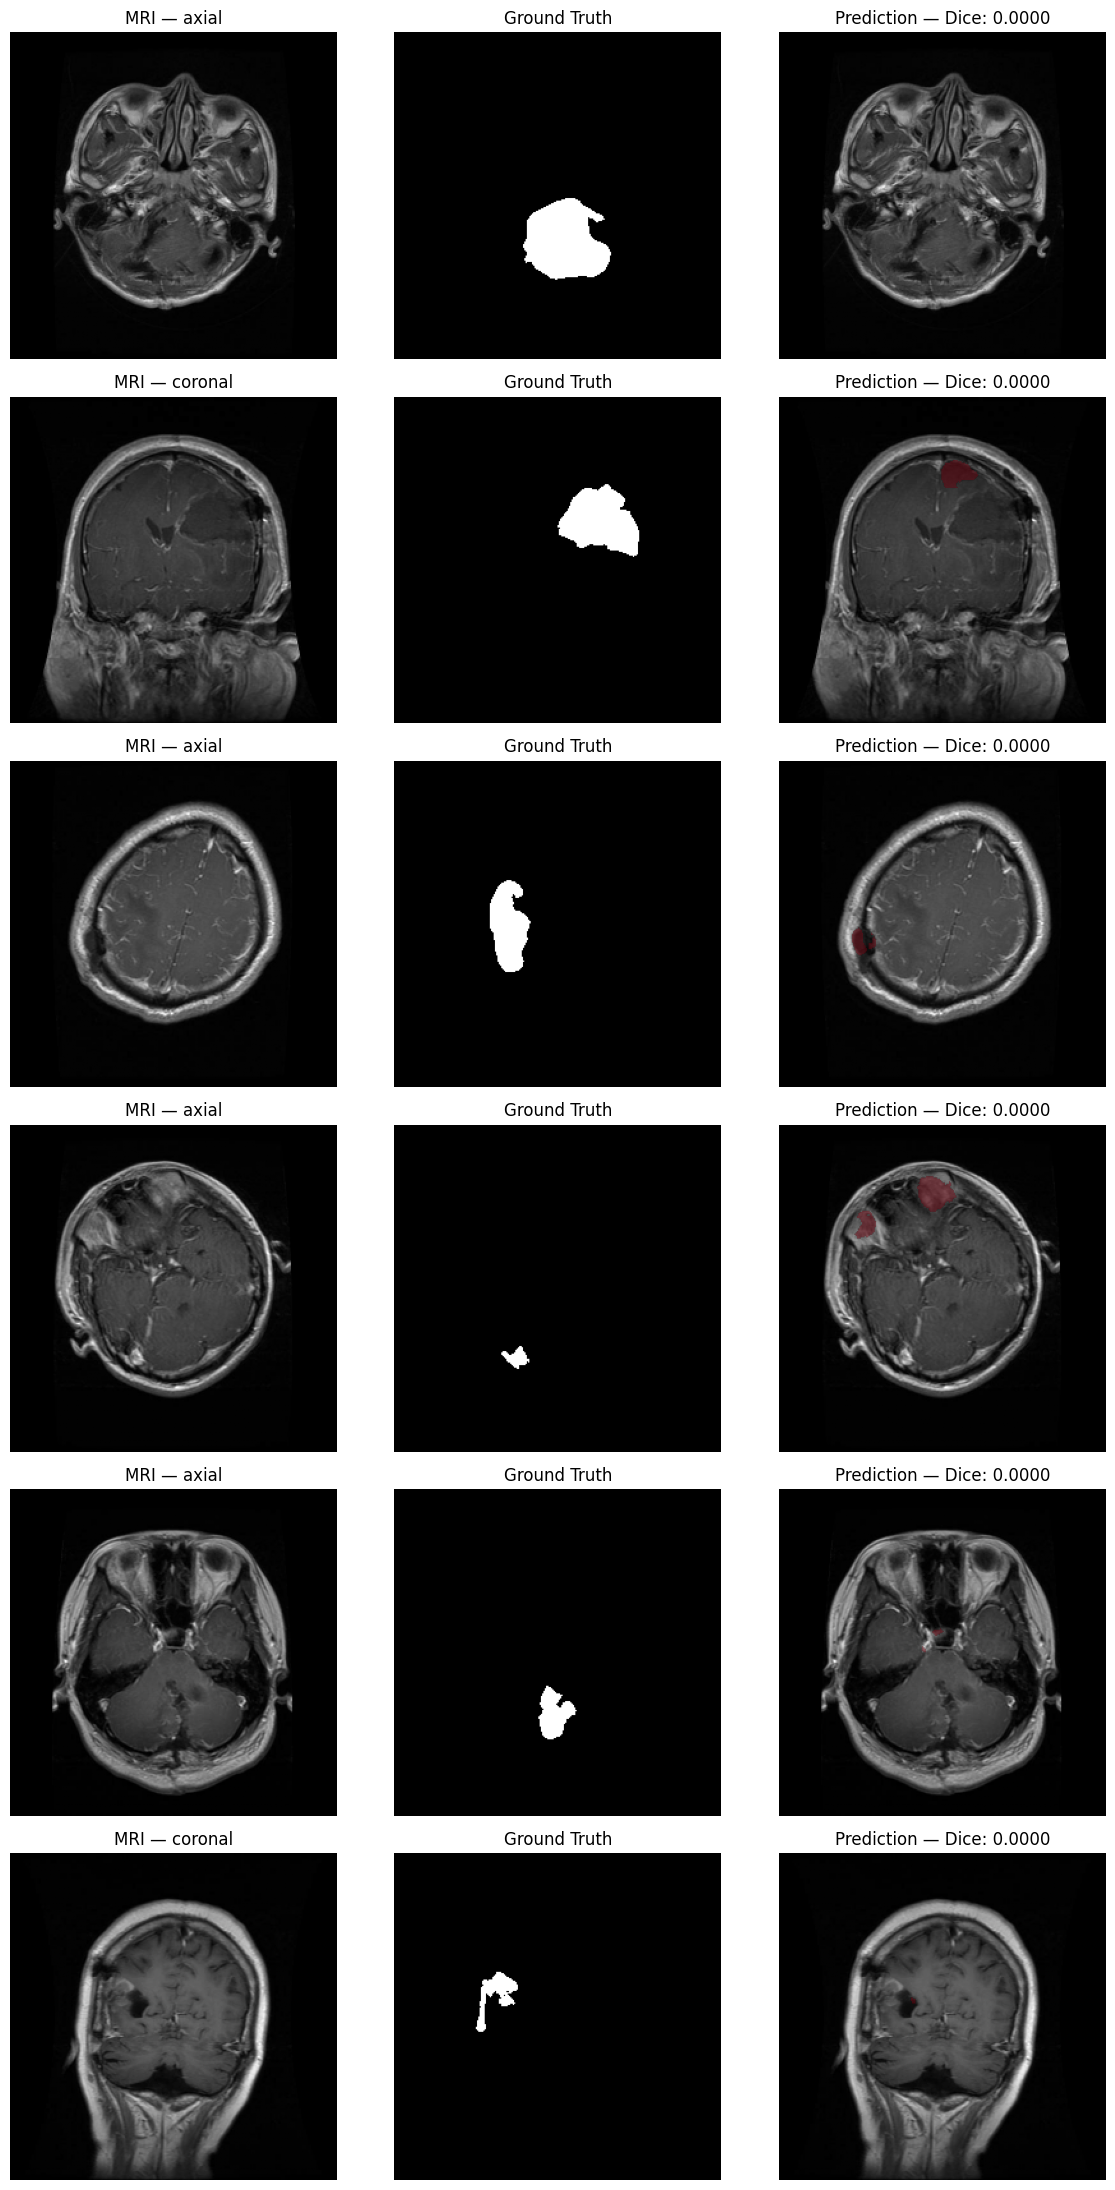

In [20]:
# Select the six worst glioma predictions
worst_gliomas = glioma_results.head(6)

fig, axes = plt.subplots(6, 3, figsize=(12, 22))

for row_idx, (_, sample) in enumerate(worst_gliomas.iterrows()):

    image_path = str(
        BRISC_ROOT / sample["image_relative_path"].replace("\\", "/")
    )

    mask_path = str(
        BRISC_ROOT / sample["mask_relative_path"].replace("\\", "/")
    )

    # Reuse the existing preprocessing function
    image, mask = preprocess_pair(image_path, mask_path)

    # Predict segmentation
    prediction = model.predict(
        tf.expand_dims(image, axis=0),
        verbose=0
    )[0, :, :, 0]

    predicted_mask = prediction >= 0.5

    # Original MRI
    axes[row_idx, 0].imshow(image[:, :, 0], cmap="gray")
    axes[row_idx, 0].set_title(
        f"MRI — {sample['plane_label']}"
    )

    # Ground-truth mask
    axes[row_idx, 1].imshow(mask[:, :, 0], cmap="gray")
    axes[row_idx, 1].set_title("Ground Truth")

    # Predicted mask overlay
    axes[row_idx, 2].imshow(image[:, :, 0], cmap="gray")

    overlay = np.ma.masked_where(
        ~predicted_mask,
        predicted_mask.astype(float)
    )

    axes[row_idx, 2].imshow(
        overlay,
        cmap="Reds",
        alpha=0.5,
        vmin=0,
        vmax=1
    )

    axes[row_idx, 2].set_title(
        f"Prediction — Dice: {sample['dice']:.4f}"
    )

    for ax in axes[row_idx]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## Conclusion

A baseline 2D U-Net was implemented and trained for binary brain tumor segmentation using the BRISC 2025 dataset.

The model was trained on 3,345 MRI images, validated on 588 images, and evaluated on a corrected held-out test set of 853 images.

### Main Results

The best checkpoint was obtained at epoch 30, with a validation Dice coefficient of 0.8351.

On the held-out test set, the model achieved:

- **Mean Dice:** 0.8209
- **Mean IoU:** 0.7412
- **Median Dice:** 0.9142

Performance varied substantially by tumor type:

| Tumor Type | Mean Dice |
|---|---:|
| Glioma | 0.6698 |
| Meningioma | 0.9256 |
| Pituitary | 0.8432 |

### Error Analysis

Glioma segmentation was identified as the main limitation of the baseline.

The glioma Dice distribution showed considerable variability, with some images achieving high overlap and others receiving near-zero scores.

Visual inspection of six poorly segmented glioma cases revealed several failure patterns, including:

- Completely missed annotated regions.
- Predictions located outside the annotated regions.
- False-positive regions combined with missed tumor areas.

Some cases also warrant further investigation of annotation quality and consistency.

### Limitations

The model showed a generalization gap between training and validation performance.


### Next Steps

Future experiments should investigate strategies to improve glioma segmentation, including data augmentation, alternative loss functions, and architecture refinements.